# 3차 실험: 하이퍼파라미터 튜닝 (Optuna)

| 항목 | 내용 |
|---|---|
| 목적 | 2차에서 가장 좋았던 입력 변형으로 상위 3개 모델(LightGBM, XGBoost, RandomForest)을 튜닝해 F1을 올린다 |
| 입력 | 2차 `results/variant_columns.json`의 최고 변형 (트리 3개 평균 F1 기준) |
| 탐색 | Optuna TPE, 목적함수 = 반복 0의 5-fold 평균 F1. 가망 없는 시도는 fold 중간에 중단(MedianPruner) |
| 최종 평가 | 고른 설정으로 10 fold(반복 0 + 1) 재평가 → 튜닝 전(2차 같은 변형)과 fold별 짝지은 보정 t-검정 |

주의: 설정을 반복 0의 fold로 골랐기 때문에, 같은 fold로 잰 점수는 조금 낙관적이다. 반복 1은 다른 방식으로 나눈 fold라서 함께 보고, 최종 판단은 마지막 차수의 테스트 세트로 한다.

실행: 2차 노트북이 먼저 실행되어 있어야 한다. 전체 약 40~50분(모델당 최대 15분 제한). `RUN_TUNE = False`면 저장된 결과를 불러온다.

In [1]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import optuna
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb, xgboost as xgb

HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "common"))
from preprocess import preprocess_train
from evaluate import load_splits, run_cv, corrected_paired_ttest
from load_features import load_all, variant_columns

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
RES = HERE / "results"; RES.mkdir(exist_ok=True)
EXP02 = HERE.parent / "exp02_feature_variants" / "results"
RUN_TUNE = True
SEED, N_JOBS = 0, 2
N_TRIALS = {"LightGBM": 40, "XGBoost": 40, "RandomForest": 20}
TIMEOUT = 900   # 모델당 최대 탐색 시간(초)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. 데이터와 입력 변형

In [2]:
df, X, y, groups = preprocess_train(HERE.parent.parent / "train.csv")
df = load_splits(df)
ALL = load_all(df, X)
vc = variant_columns()
VARIANT = vc["best_variant"]
use_cols = vc["columns"][VARIANT]
dev = (df["set"] == "dev").values
Xd = ALL.loc[dev, use_cols].reset_index(drop=True); yd = y[dev]
folds = df.loc[dev, ["fold_r0", "fold_r1"]].reset_index(drop=True)
print("2차 변형별 트리 3개 평균 F1:", vc["tree_mean_f1"])
print("사용할 변형:", VARIANT, "| 개발 세트:", Xd.shape)

2차 변형별 트리 3개 평균 F1: {'+ap_tt': 0.8164, '+maccs': 0.817, '+mordred': 0.8128, '+ptfp': 0.8164, '+rdkit217': 0.8128, 'count_chiral': 0.8149, 'svd': 0.8}
사용할 변형: +maccs | 개발 세트: (6400, 1167)


## 2. 탐색 공간

| 모델 | 탐색하는 하이퍼파라미터 |
|---|---|
| LightGBM | 트리 수 200~1500, 학습률 0.01~0.1, 잎 수 15~127, 잎 최소 샘플 5~100, 컬럼 샘플링 0.05~0.6, 행 샘플링 0.6~1.0, L1·L2 정규화 |
| XGBoost | 트리 수 200~1500, 학습률 0.01~0.1, 깊이 3~10, min_child_weight 1~20, 컬럼 샘플링 0.05~0.6, 행 샘플링 0.6~1.0, gamma, L2 정규화 |
| RandomForest | 트리 수 300~800, 분할 후보 컬럼(sqrt, log2, 5%, 10%), 잎 최소 샘플 1~10, 최대 깊이, 클래스 가중치 |

In [3]:
def make(algo, p):
    if algo == "LightGBM":
        return lgb.LGBMClassifier(**p, subsample_freq=1, verbose=-1, random_state=SEED, n_jobs=N_JOBS)
    if algo == "XGBoost":
        return xgb.XGBClassifier(**p, tree_method="hist", eval_metric="logloss", random_state=SEED, n_jobs=N_JOBS)
    return RandomForestClassifier(**p, n_jobs=N_JOBS, random_state=SEED)

def space(algo, t):
    if algo == "LightGBM":
        return dict(n_estimators=t.suggest_int("n_estimators", 200, 1500, step=100),
                    learning_rate=t.suggest_float("learning_rate", 0.01, 0.1, log=True),
                    num_leaves=t.suggest_int("num_leaves", 15, 127, log=True),
                    min_child_samples=t.suggest_int("min_child_samples", 5, 100, log=True),
                    colsample_bytree=t.suggest_float("colsample_bytree", 0.05, 0.6),
                    subsample=t.suggest_float("subsample", 0.6, 1.0),
                    reg_alpha=t.suggest_float("reg_alpha", 1e-3, 10, log=True),
                    reg_lambda=t.suggest_float("reg_lambda", 1e-3, 10, log=True))
    if algo == "XGBoost":
        return dict(n_estimators=t.suggest_int("n_estimators", 200, 1500, step=100),
                    learning_rate=t.suggest_float("learning_rate", 0.01, 0.1, log=True),
                    max_depth=t.suggest_int("max_depth", 3, 10),
                    min_child_weight=t.suggest_float("min_child_weight", 1, 20, log=True),
                    colsample_bytree=t.suggest_float("colsample_bytree", 0.05, 0.6),
                    subsample=t.suggest_float("subsample", 0.6, 1.0),
                    gamma=t.suggest_float("gamma", 1e-3, 5, log=True),
                    reg_lambda=t.suggest_float("reg_lambda", 1e-2, 20, log=True))
    mf = t.suggest_categorical("max_features", ["sqrt", "log2", "0.05", "0.1"])
    return dict(n_estimators=t.suggest_int("n_estimators", 300, 800, step=100),
                max_features=float(mf) if mf[0] == "0" else mf,
                min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 10),
                max_depth=t.suggest_categorical("max_depth", [None, 20, 40]),
                class_weight=t.suggest_categorical("class_weight", [None, "balanced_subsample"]))

def objective(algo):
    f0 = folds["fold_r0"].values
    def obj(t):
        p = space(algo, t); f1s = []
        for k in range(5):
            tr, va = f0 != k, f0 == k
            m = make(algo, p); m.fit(Xd[tr], yd[tr])
            f1s.append(f1_score(yd[va], m.predict_proba(Xd[va])[:, 1] >= 0.5))
            t.report(np.mean(f1s), k)
            if t.should_prune(): raise optuna.TrialPruned()
        return float(np.mean(f1s))
    return obj

## 3. 탐색 실행

In [4]:
studies, best_params = {}, {}
if RUN_TUNE:
    for algo in ["LightGBM", "XGBoost", "RandomForest"]:
        t0 = time.time()
        st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                                 pruner=optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=1))
        st.optimize(objective(algo), n_trials=N_TRIALS[algo], timeout=TIMEOUT)
        studies[algo] = st
        bp = space(algo, optuna.trial.FixedTrial(st.best_params))
        best_params[algo] = bp
        st.trials_dataframe().to_csv(RES / f"trials_{algo}.csv", index=False)
        n_done = sum(t.state.name == "COMPLETE" for t in st.trials); n_pr = sum(t.state.name == "PRUNED" for t in st.trials)
        print(f"{algo:12s} best F1(반복0) {st.best_value:.4f} | 완료 {n_done} · 중단 {n_pr} | {time.time()-t0:.0f}s", flush=True)
    json.dump({"variant": VARIANT, "params": best_params}, open(RES / "best_params.json", "w"), default=str)
else:
    best_params = json.load(open(RES / "best_params.json"))["params"]
for a, p in best_params.items():
    print(a, p)

LightGBM     best F1(반복0) 0.8251 | 완료 19 · 중단 1 | 929s


XGBoost      best F1(반복0) 0.8224 | 완료 19 · 중단 4 | 900s


RandomForest best F1(반복0) 0.8219 | 완료 18 · 중단 2 | 625s


LightGBM {'n_estimators': 1500, 'learning_rate': 0.01423775232179972, 'num_leaves': 38, 'min_child_samples': 9, 'colsample_bytree': 0.4628538973580312, 'subsample': 0.6009759607204782, 'reg_alpha': 0.006598062453200796, 'reg_lambda': 0.07227543814882728}
XGBoost {'n_estimators': 1400, 'learning_rate': 0.013349349615739858, 'max_depth': 10, 'min_child_weight': 2.5188677565454487, 'colsample_bytree': 0.47148642740145164, 'subsample': 0.7748032542992811, 'gamma': 0.004216735698333357, 'reg_lambda': 0.05824716307078541}
RandomForest {'n_estimators': 600, 'max_features': 0.1, 'min_samples_leaf': 1, 'max_depth': None, 'class_weight': None}


## 4. 고른 설정으로 10 fold 재평가 (튜닝 전과 비교)

In [5]:
if RUN_TUNE:
    sc, oo = [], {}
    for algo, p in best_params.items():
        s, o = run_cv(lambda: make(algo, p), Xd, yd, folds, f"tuned|{algo}")
        sc.append(s)
        for r in o.columns: oo[f"tuned|{algo}|{r}"] = o[r].values
        print(f"{algo:12s} F1 {s.f1.mean():.4f} ± {s.f1.std(ddof=0):.4f} | AUC {s.auc.mean():.4f}", flush=True)
    scores = pd.concat(sc, ignore_index=True)
    oof = pd.DataFrame(oo); oof.insert(0, "SMILES", df.loc[dev, "SMILES"].values); oof.insert(1, "label", yd)
    scores.to_csv(RES / "cv_scores.csv", index=False); oof.to_csv(RES / "oof_predictions.csv", index=False)
else:
    scores = pd.read_csv(RES / "cv_scores.csv"); oof = pd.read_csv(RES / "oof_predictions.csv")

s2 = pd.read_csv(EXP02 / "cv_scores.csv")
before = s2[s2.model.isin([f"{VARIANT}|{a}" for a in best_params])].copy()
before["model"] = before.model.str.replace(f"{VARIANT}|", "before|", regex=False)
allsc = pd.concat([before, scores], ignore_index=True)
allsc[["stage", "algo"]] = allsc.model.str.split("|", expand=True)

rows = []
for a in best_params:
    sub = allsc[allsc.algo == a].copy(); sub["model"] = sub.stage
    t = corrected_paired_ttest(sub, "before").loc["tuned"]
    b, tu = sub[sub.stage == "before"], sub[sub.stage == "tuned"]
    rows.append((a, b.f1.mean(), tu.f1.mean(), t.diff_vs_best, t.p_value, int(t.wins),
                 tu[tu.repeat == 0].f1.mean() - b[b.repeat == 0].f1.mean(), tu[tu.repeat == 1].f1.mean() - b[b.repeat == 1].f1.mean(),
                 b.auc.mean(), tu.auc.mean()))
cmp = pd.DataFrame(rows, columns=["모델", "튜닝 전 F1", "튜닝 후 F1", "차이", "p값", "10 fold 중 개선", "차이(반복0, 탐색에 씀)",
                                  "차이(반복1)", "튜닝 전 AUC", "튜닝 후 AUC"]).set_index("모델")
cmp.to_csv(RES / "before_after.csv")
display(cmp.round(4))

LightGBM     F1 0.8215 ± 0.0069 | AUC 0.8832


XGBoost      F1 0.8218 ± 0.0059 | AUC 0.8824


RandomForest F1 0.8212 ± 0.0049 | AUC 0.8772


,튜닝 전 F1,튜닝 후 F1,차이,p값,10 fold 중 개선,"차이(반복0, 탐색에 씀)",차이(반복1),튜닝 전 AUC,튜닝 후 AUC
모델,,,,,,,,,
LightGBM,0.8178,0.8215,0.0037,0.2844,7,0.0053,0.0021,0.8774,0.8832
XGBoost,0.8142,0.8218,0.0076,0.0050,10,0.0073,0.0080,0.8747,0.8824
RandomForest,0.8190,0.8212,0.0022,0.4677,8,0.0030,0.0013,0.8748,0.8772


## 5. 시각화

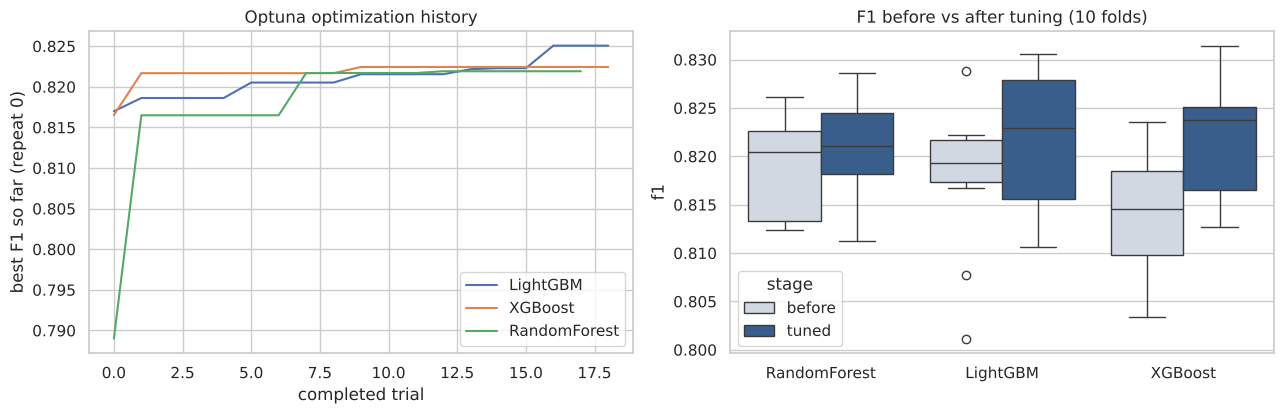

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
if RUN_TUNE:
    for a, st in studies.items():
        v = [t.value for t in st.trials if t.state.name == "COMPLETE"]
        ax[0].plot(np.maximum.accumulate(v), label=a)
    ax[0].set_xlabel("completed trial"); ax[0].set_ylabel("best F1 so far (repeat 0)"); ax[0].set_title("Optuna optimization history"); ax[0].legend()
sns.boxplot(data=allsc, x="algo", y="f1", hue="stage", ax=ax[1], palette=["#cfd8e3", "#2b5d9a"])
ax[1].set_title("F1 before vs after tuning (10 folds)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(RES / "fig_tuning.png", dpi=130); plt.show()

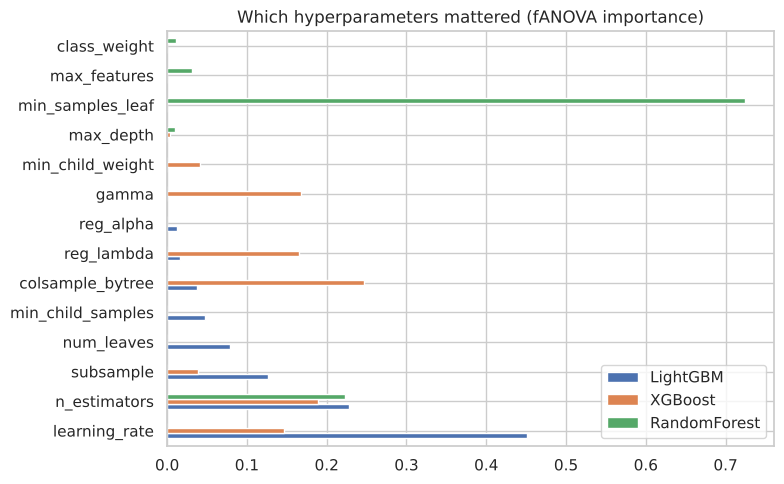

In [7]:
if RUN_TUNE:
    imp = {}
    for a, st in studies.items():
        try: imp[a] = optuna.importance.get_param_importances(st)
        except Exception as e: print(a, e)
    imp = pd.DataFrame(imp).fillna(0)
    imp.to_csv(RES / "param_importance.csv")
else:
    imp = pd.read_csv(RES / "param_importance.csv", index_col=0)
imp.plot.barh(figsize=(8, 5), title="Which hyperparameters mattered (fANOVA importance)")
plt.tight_layout(); plt.savefig(RES / "fig_param_importance.png", dpi=130); plt.show()

## 6. 결론과 4차로 넘길 것

결과 표는 4절, 그래프는 5절 참고.

### 판단
1. 세 모델 모두 F1 0.821~0.822로 올라왔다. 1차 최고(0.8177)보다 약 +0.004 높다.
2. 의미 있는 개선은 XGBoost뿐이다(+0.0076, p = 0.005, 10 fold 모두 개선). 탐색에 쓰지 않은 반복 1에서도 +0.008로 유지됐다.
3. LightGBM은 탐색 중에는 0.825였지만 10 fold 재평가에서는 0.8215로 내려왔다. 반복 1의 개선은 +0.002뿐이다. 탐색 점수가 낙관적이었다는 뜻이고, 그래서 탐색 점수가 아니라 10 fold 재평가 점수로 판단한다.
4. 공통 경향: 학습률을 낮추고(0.013~0.014) 트리 수를 늘렸다(1,400~1,500). 컬럼 샘플링은 기본 0.3에서 0.46~0.47로 올랐다. 2차에서 컬럼을 늘렸을 때 핵심 변수가 덜 뽑혔던 문제와 맞닿아 있다.
5. AUC는 0.882~0.883으로 1차(0.876)보다 올랐다. 순위를 매기는 능력 자체도 좋아졌다.

### 4차로 넘길 것
- 튜닝된 3개 모델의 OOF 예측(`results/oof_predictions.csv`)이 앙상블의 중심 재료다.
- 세 모델의 점수가 거의 같다(0.8212~0.8218). 하나를 고르기보다 섞는 쪽이 안정적일 가능성이 크다.

### 제출 파일
- `predict_output_임채현_3차.csv`: 3차 단일 최고(튜닝된 XGBoost, CV F1 0.8218)를 8,000행 전체로 재학습해 예측했다. 테스트 세트(1,600행) F1은 0.809, AUC 0.875로 CV(0.822)보다 낮았다. 1차 RandomForest(테스트 0.813)·2차(0.821)보다도 낮다. 테스트 1,600행 한 번의 점수는 ±0.01 정도 흔들리므로 이것만으로 튜닝이 해로웠다고 단정할 수는 없다. 다만 튜닝 이득(+0.004~0.008)이 이 흔들림보다 작다는 뜻이므로, 단일 모델 하나에 기대기보다 4차 앙상블로 안정성을 높이는 것이 낫다.

